## Linear Regression

**Ví dụ: dữ liệu ngẫu nhiên (hoặc dữ liệu thực tế) để dự đoán mối quan hệ giữa hai biến.**

Hệ số chặn (Intercept): [4.20634019]
Hệ số góc (Slope): [[2.9902591]]
Mean Squared Error (MSE): 0.9177532469714291
R^2 score: 0.6521157503858556


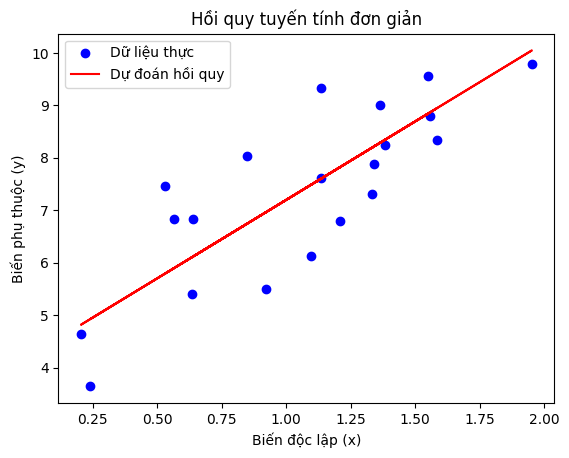

In [ ]:
# Thư viện cần thiết
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Tạo dữ liệu ngẫu nhiên
# x là biến đầu vào, y là biến đầu ra
np.random.seed(0)
x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + np.random.randn(100, 1) # Đường thẳng với nhiễu

# Chia dữ liệu thành tập huấn luyện và tập kiểm tra
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình trên tập huấn luyện
model.fit(x_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(x_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}")

# Vẽ biểu đồ
plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn giản")
plt.xlabel("Biến độc lập (x)")
plt.ylabel("Biến phụ thuộc (y)")
plt.legend()
plt.show()


### Hồi quy tuyến tính đa biến

**Ví dụ: với dữ liệu có nhiều biến đầu vào.**

In [ ]:
# Thư viện
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Tạo dữ liệu giả lập với nhiều biến đầu vào
np.random.seed(0)
X = 2 * np.random.rand(100, 3) # 3 biến đầu vào
y = 4 + 3 * X[:, 0] + 2 * X[:, 1] + 5 * X[:, 2] + np.random.randn(100, 1)

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")


Hệ số chặn (Intercept): [16.19760926 15.43919644 19.84557989 14.77283548 11.83735151 12.94618486
 21.95150953 18.46249761  8.71920053 15.9183632  13.26210877 13.67845488
 19.59412812 13.91560995 15.11069323 10.17095745 13.06571791 11.62188955
 12.44591888  9.84558564 11.97495097  9.31901587 17.71015057 13.18527734
 19.68892141  6.58465723  9.44792087 13.68322616 13.70998424 16.17672804
  9.91537087 11.30383823 15.9052451   9.45585575 14.76378676 15.5639678
 13.63707664 14.86707566 19.29617887 17.9562316  19.93399657 15.63963054
 11.93953084 12.51655138 11.72195981 16.39088277 18.62009633 16.88440148
 12.67132415 22.37866796 10.01046042 16.68505662 15.20848669 11.7564809
 21.56941496 12.79779405 14.29316516  5.32756899 13.12773879 12.72087168
 13.26270144 15.32020949 16.89099403  9.57932872 16.30649256 10.41231319
  9.2201373  11.50144208 11.22733564 17.85154785 17.45674067 13.26266181
 13.35346663 20.24506167 10.706136   14.63811683 15.16340021  7.62563891
 10.70159914 13.77614785 14.8

## Logistic Regression

**Hồi quy Logistic với bộ dữ liệu hoa Iris:**

In [ ]:
# Thư viện
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Tải dữ liệu hoa Iris trong thư viện sklearn
iris = load_iris()
X = iris['data'] # Các đặc trưng (features)
y = iris['target'] # Các nhãn (target)

# Chọn ra hai loại hoa (0 và 1) để thực hiện phân loại nhị phân
X = X[y != 2] # Loại bỏ lớp 2
y = y[y != 2] # Chỉ giữ lại lớp 0 và 1

# Chia dữ liệu (minh họa chia 80% huấn luyện và 20% kiểm tra)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình Logistic Regression
model = LogisticRegression()

# Huấn luyện mô hình trên tập huấn luyện
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

# In kết quả
print(f"Độ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("Báo cáo phân loại (Classification Report):")
print(class_report)


Độ chính xác (Accuracy): 1.0
Ma trận nhầm lẫn (Confusion Matrix):
[[12  0]
 [ 0  8]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



## Bài tập ở lớp

**Bài 1:**

In [ ]:
# Thư viện
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# 1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên Diện tích nhà.

# Tạo dữ liệu giả lập
np.random.seed(0)
X = 100 * np.random.rand(100, 1) # Diện tích nhà (m2)
y = 500 + 30 * X + 100 * np.random.randn(100, 1) # Giá bán (triệu VND)

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}\n")

# 2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.

# Tạo dữ liệu giả lập
np.random.seed(0)
X = 100 * np.random.rand(500, 1) # Tăng số lượng dữ liệu lên 500
y = 500 + 30 * X + 500 * np.random.randn(500, 1) # Tăng độ nhiễu

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}\n")

# 3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.

# Tạo dữ liệu giả lập với nhiều biến đầu vào
np.random.seed(0)
X = 100 * np.random.rand(100, 3) # 3 biến đầu vào
y = 500 + 30 * X[:, 0] + 20 * X[:, 1] + 50 * X[:, 2] + 100 * np.random.randn(100)

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")

Hệ số chặn (Intercept): [520.63401887]
Hệ số hồi quy (Coefficients): [[29.9805182]]
Mean Squared Error (MSE): 9177.532469714282

Hệ số chặn (Intercept): [433.45764448]
Hệ số hồi quy (Coefficients): [[30.33586399]]
Mean Squared Error (MSE): 221922.8379977781

Hệ số chặn (Intercept): 501.63370124709854
Hệ số hồi quy (Coefficients): [29.86875977 19.76007822 50.08711696]
Mean Squared Error (MSE): 10964.652490523125


**Bài 2:**

Xác suất dự đoán mắc bệnh (lớp 1):
[9.99567450e-01 6.46914985e-04 9.99999695e-01 9.99244533e-01
 9.99166043e-01 9.99432204e-01 8.63243409e-01 1.38898599e-01
 9.99965748e-01 9.83279661e-01 9.99951554e-01 3.95521828e-02
 9.95954649e-01 9.89805467e-01 1.40698685e-01 7.05973786e-01
 6.16080002e-02 1.02832924e-03 9.89704569e-01 9.99946445e-01]

Nhãn dự đoán:
[1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 1 0 0 1 1]

Độ chính xác (Accuracy): 0.9
Ma trận nhầm lẫn (Confusion Matrix):
[[ 5  1]
 [ 1 13]]


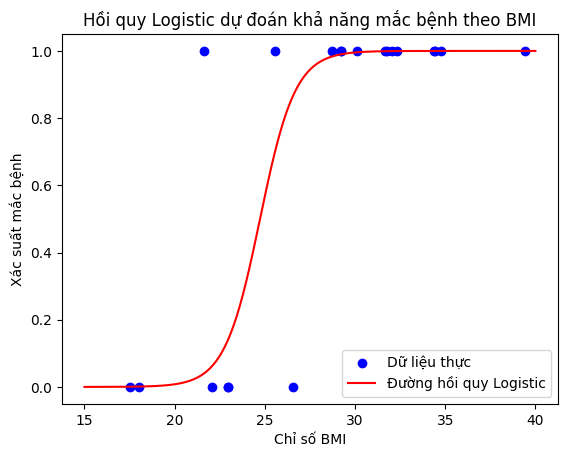

In [ ]:
# Thư viện
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic

np.random.seed(0)
X = 15 + 25 * np.random.rand(100, 1) # Chỉ số BMI từ 15 đến 40
y = (X[:, 0] + np.random.randn(100) * 2 > 25).astype(int) # BMI > 25 có khả năng mắc bệnh (1)

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Sử dụng thư viện phù hợp để xây dựng một mô hình hồi quy logistic

model = LogisticRegression()

# 3. Huấn luyện mô hình trên tập dữ liệu mẫu

model.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra

y_prob = model.predict_proba(X_test)[:, 1] # Xác suất mắc bệnh (lớp 1)
y_pred = model.predict(X_test) # Nhãn dự đoán (0 hoặc 1)

# 5. Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

# In kết quả
print("Xác suất dự đoán mắc bệnh (lớp 1):")
print(y_prob)
print("\nNhãn dự đoán:")
print(y_pred)
print(f"\nĐộ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)

# 6. Trực quan hóa dữ liệu và đường hồi quy logistic

X_range = np.linspace(15, 40, 300).reshape(-1, 1)
y_sigmoid = model.predict_proba(X_range)[:, 1]

plt.scatter(X_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(X_range, y_sigmoid, color="red", label="Đường hồi quy Logistic")
plt.title("Hồi quy Logistic dự đoán khả năng mắc bệnh theo BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.show()


**Bài 3:**

--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN ---
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

--- THÔNG TIN CẤU TRÚC DỮ LIỆU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-nul

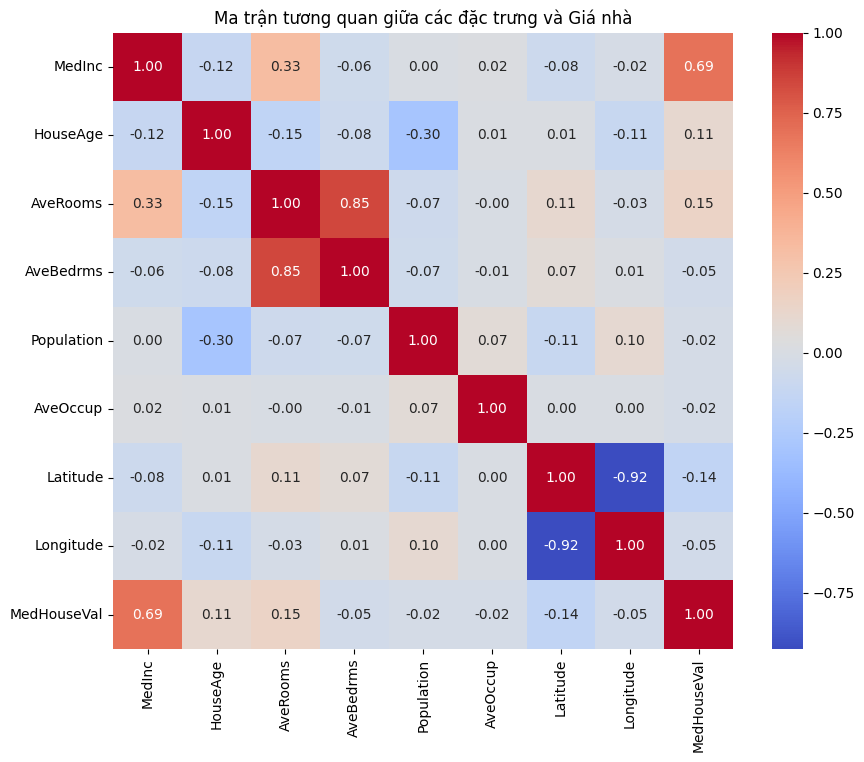

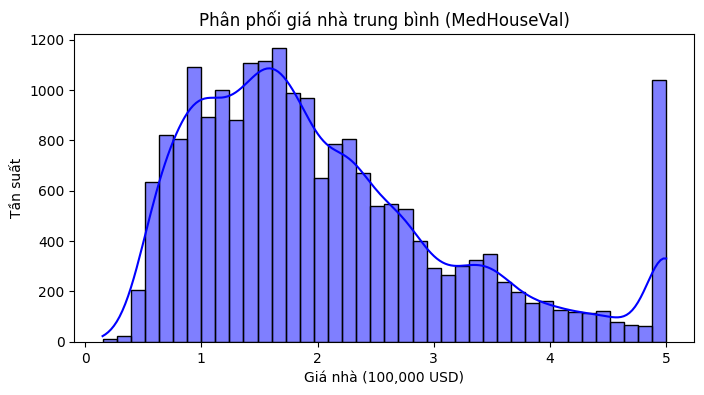


Kích thước dữ liệu sau khi lọc ngoại lai cực đoan: (19389, 9)

--- ĐÁNH GIÁ VÀ SO SÁNH CÁC MÔ HÌNH ---

Mô hình: Linear Regression
  - MAE : 0.4822
  - MSE : 0.4268
  - RMSE: 0.6533
  - R^2 : 0.6874

Mô hình: Ridge Regression (alpha=1.0)
  - MAE : 0.4822
  - MSE : 0.4268
  - RMSE: 0.6533
  - R^2 : 0.6874

Mô hình: Lasso Regression (alpha=0.01)
  - MAE : 0.4832
  - MSE : 0.4302
  - RMSE: 0.6559
  - R^2 : 0.6849

Hệ số chặn (Intercept): 2.0825

--- MỨC ĐỘ ẢNH HƯỞNG CỦA CÁC ĐẶC TRƯNG ---
Đặc trưng (Feature)  Hệ số hồi quy (Weight)
             MedInc                0.834117
           HouseAge                0.148255
          AveBedrms                0.116222
         Population                0.049071
           AveRooms               -0.132967
           AveOccup               -0.271145
          Longitude               -0.850866
           Latitude               -0.922524


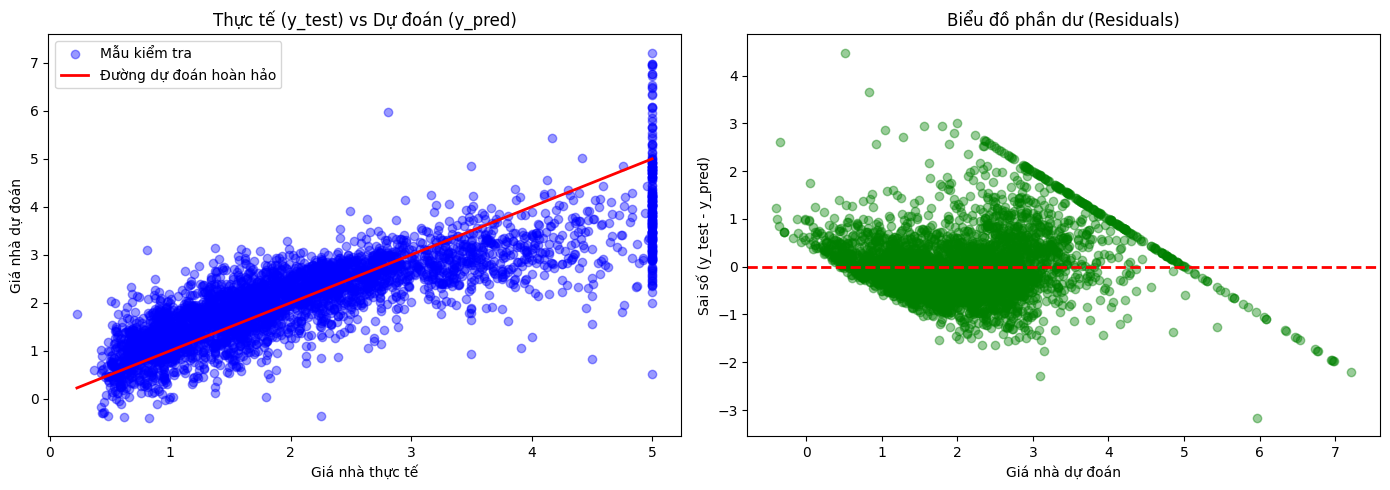

In [ ]:
# Thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tải và khám phá tổng quan bộ dữ liệu (California Housing)

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['MedHouseVal'] = housing.target # Biến mục tiêu: Giá nhà trung bình (100,000 USD)

print("--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN ---")
print(df.head())

print("\n--- THÔNG TIN CẤU TRÚC DỮ LIỆU ---")
print(df.info())

print("\n--- THỐNG KÊ MÔ TẢ CÁC ĐẶC TRƯNG ---")
print(df.describe().T)

# 2. Đánh giá thực trạng dữ liệu (EDA)

# Kiểm tra giá trị thiếu và dữ liệu trùng lặp
print("\n--- KIỂM TRA DỮ LIỆU THIẾU & TRÙNG LẶP ---")
print("Số lượng giá trị thiếu:\n", df.isnull().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())

# Trực quan hóa ma trận tương quan (Correlation Matrix)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan giữa các đặc trưng và Giá nhà")
plt.show()

# Trực quan hóa phân phối của biến mục tiêu (MedHouseVal)
plt.figure(figsize=(8, 4))
sns.histplot(df['MedHouseVal'], bins=40, kde=True, color="blue")
plt.title("Phân phối giá nhà trung bình (MedHouseVal)")
plt.xlabel("Giá nhà (100,000 USD)")
plt.ylabel("Tần suất")
plt.show()

# 3. Tiền xử lý dữ liệu

# Xử lý giá trị ngoại lai (Outliers) cực đoan bằng phương pháp IQR cho các cột có độ lệch lớn
for col in ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3 * IQR
    upper_bound = Q3 + 3 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print(f"\nKích thước dữ liệu sau khi lọc ngoại lai cực đoan: {df.shape}")

# Tách biến độc lập (X) và biến phụ thuộc (y)
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

# Chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa dữ liệu (Standardization) về trung bình 0, phương sai 1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Huấn luyện và so sánh các mô hình hồi quy (Linear, Ridge, Lasso)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression (alpha=1.0)": Ridge(alpha=1.0),
    "Lasso Regression (alpha=0.01)": Lasso(alpha=0.01)
}

print("\n--- ĐÁNH GIÁ VÀ SO SÁNH CÁC MÔ HÌNH ---")
for name, model in models.items():
    # Huấn luyện mô hình
    model.fit(X_train_scaled, y_train)

    # Dự đoán trên tập kiểm tra
    y_pred = model.predict(X_test_scaled)

    # Tính toán các độ đo đánh giá
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f"\nMô hình: {name}")
    print(f"  - MAE : {mae:.4f}")
    print(f"  - MSE : {mse:.4f}")
    print(f"  - RMSE: {rmse:.4f}")
    print(f"  - R^2 : {r2:.4f}")

# 5. Phân tích chi tiết mô hình Linear Regression chính

best_model = LinearRegression()
best_model.fit(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)

# Bảng mức độ ảnh hưởng (trọng số) của từng đặc trưng
coef_df = pd.DataFrame({
    'Đặc trưng (Feature)': X.columns,
    'Hệ số hồi quy (Weight)': best_model.coef_
}).sort_values(by='Hệ số hồi quy (Weight)', ascending=False)

print(f"\nHệ số chặn (Intercept): {best_model.intercept_:.4f}")
print("\n--- MỨC ĐỘ ẢNH HƯỞNG CỦA CÁC ĐẶC TRƯNG ---")
print(coef_df.to_string(index=False))

# 6. Trực quan hóa kết quả dự đoán và phân tích phần dư (Residuals)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Giá trị thực tế vs Giá trị dự đoán
axes[0].scatter(y_test, y_pred_best, color="blue", alpha=0.4, label="Mẫu kiểm tra")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", lw=2, label="Đường dự đoán hoàn hảo")
axes[0].set_title("Thực tế (y_test) vs Dự đoán (y_pred)")
axes[0].set_xlabel("Giá nhà thực tế")
axes[0].set_ylabel("Giá nhà dự đoán")
axes[0].legend()

# Biểu đồ 2: Biểu đồ phân dư (Residuals Plot)
residuals = y_test - y_pred_best
axes[1].scatter(y_pred_best, residuals, color="green", alpha=0.4)
axes[1].axhline(y=0, color="red", linestyle="--", lw=2)
axes[1].set_title("Biểu đồ phần dư (Residuals)")
axes[1].set_xlabel("Giá nhà dự đoán")
axes[1].set_ylabel("Sai số (y_test - y_pred)")

plt.tight_layout()
plt.show()
